In [ ]:
!pip install dmba

In [2]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import accuracy_score

import matplotlib.pylab as plt

from dmba import classificationSummary
from dmba import AIC_score
from dmba import backward_elimination, forward_selection, stepwise_selection

%matplotlib inline

%matplotlib inline

from pathlib import Path

import seaborn as sns

import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
import matplotlib.pylab as plt
import dmba
from dmba import plotDecisionTree, classificationSummary, regressionSummary

no display found. Using non-interactive Agg backend


In [3]:
# loaded data
lcd_df = pd.read_csv("lending_club.csv")

lcd_df.head()

,Unnamed: 0,loan_status,annual_inc,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,open_acc,revol_bal,revol_util,total_acc
0,133423,Fully Paid,125000.0,20.81,0.0,675.0,679.0,0.0,24.0,15.0,23337.0,58.9,23.0
1,557225,Late (31-120 days),23500.0,23.95,0.0,665.0,669.0,0.0,33.0,5.0,4009.0,35.5,11.0
2,80694,Current,63000.0,8.72,0.0,745.0,749.0,1.0,NaN,6.0,3045.0,20.7,10.0
3,651321,Fully Paid,40000.0,31.09,1.0,680.0,684.0,1.0,13.0,14.0,24950.0,53.8,26.0
4,150555,Current,90000.0,19.72,1.0,705.0,709.0,3.0,5.0,12.0,12729.0,23.2,26.0


In [4]:
lcd_df.rename(columns={"Unnamed: 0": "loan_id"}, inplace=True)

In [5]:
lcd_df.columns

Index(['loan_id', 'loan_status', 'annual_inc', 'dti', 'delinq_2yrs',
       'fico_range_low', 'fico_range_high', 'inq_last_6mths',
       'mths_since_last_delinq', 'open_acc', 'revol_bal', 'revol_util',
       'total_acc'],
      dtype='object')

In [6]:
# variable names
lcd_df.columns = [c.replace(' ', '_') for c in lcd_df.columns]
lcd_df.columns = [c.replace('&', '') for c in lcd_df.columns]
lcd_df.columns = [c.replace('/', '_') for c in lcd_df.columns]

In [7]:
pd.set_option('display.max_columns', None)

In [8]:
lcd_df.columns

Index(['loan_id', 'loan_status', 'annual_inc', 'dti', 'delinq_2yrs',
       'fico_range_low', 'fico_range_high', 'inq_last_6mths',
       'mths_since_last_delinq', 'open_acc', 'revol_bal', 'revol_util',
       'total_acc'],
      dtype='object')

In [9]:
lcd_df.describe           

<bound method NDFrame.describe of         loan_id         loan_status  annual_inc    dti  delinq_2yrs  \
0        133423          Fully Paid    125000.0  20.81          0.0   
1        557225  Late (31-120 days)     23500.0  23.95          0.0   
2         80694             Current     63000.0   8.72          0.0   
3        651321          Fully Paid     40000.0  31.09          1.0   
4        150555             Current     90000.0  19.72          1.0   
...         ...                 ...         ...    ...          ...   
104853   545353             Current    120000.0  13.27          1.0   
104854   906734          Fully Paid     47000.0  26.92          1.0   
104855   796286             Current     67000.0   2.24          0.0   
104856   954087          Fully Paid    100000.0  15.23          0.0   
104857   189199          Fully Paid     50000.0  28.95          0.0   

        fico_range_low  fico_range_high  inq_last_6mths  \
0                675.0            679.0             0.

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

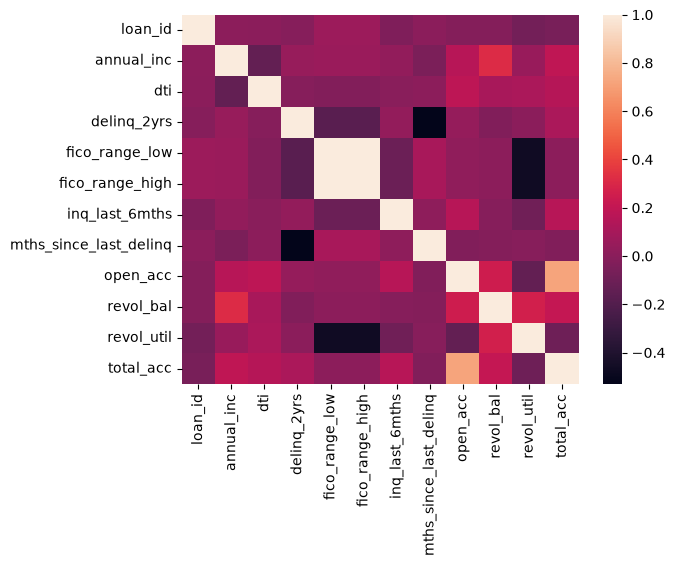

In [11]:
numeric_lcd_df = lcd_df.select_dtypes(include='number')

sns.heatmap(numeric_lcd_df.corr())
plt.show()

In [12]:
# Creating the new column "charge_off"

lcd_df['charge_off'] = np.where(lcd_df['loan_status'] == 'Charged Off', 1, 0)
print(lcd_df)

        loan_id         loan_status  annual_inc    dti  delinq_2yrs  \
0        133423          Fully Paid    125000.0  20.81          0.0   
1        557225  Late (31-120 days)     23500.0  23.95          0.0   
2         80694             Current     63000.0   8.72          0.0   
3        651321          Fully Paid     40000.0  31.09          1.0   
4        150555             Current     90000.0  19.72          1.0   
...         ...                 ...         ...    ...          ...   
104853   545353             Current    120000.0  13.27          1.0   
104854   906734          Fully Paid     47000.0  26.92          1.0   
104855   796286             Current     67000.0   2.24          0.0   
104856   954087          Fully Paid    100000.0  15.23          0.0   
104857   189199          Fully Paid     50000.0  28.95          0.0   

        fico_range_low  fico_range_high  inq_last_6mths  \
0                675.0            679.0             0.0   
1                665.0       

In [13]:
# summary statistics of newly created variable

summary_stats = lcd_df[['charge_off']].describe()

print("\nSummary statistics:")
print(summary_stats)


Summary statistics:
          charge_off
count  104858.000000
mean        0.122556
std         0.327929
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000


In [14]:
na_count = lcd_df.isna().sum()

print(na_count)

loan_id                       0
loan_status                   3
annual_inc                    3
dti                          84
delinq_2yrs                   3
fico_range_low                3
fico_range_high               3
inq_last_6mths                3
mths_since_last_delinq    52600
open_acc                      3
revol_bal                     3
revol_util                   82
total_acc                     3
charge_off                    0
dtype: int64


In [15]:
column_data_types = lcd_df.dtypes

print(column_data_types)

loan_id                     int64
loan_status                object
annual_inc                float64
dti                       float64
delinq_2yrs               float64
fico_range_low            float64
fico_range_high           float64
inq_last_6mths            float64
mths_since_last_delinq    float64
open_acc                  float64
revol_bal                 float64
revol_util                float64
total_acc                 float64
charge_off                  int64
dtype: object


In [16]:
lcd_df['annual_inc'] = lcd_df['annual_inc'].fillna(lcd_df['annual_inc'].median())
lcd_df['dti'] = lcd_df['dti'].fillna(lcd_df['dti'].median())
lcd_df['deling_2yrs'] = lcd_df['delinq_2yrs'].fillna(lcd_df['delinq_2yrs'].median())
lcd_df['fico_range_low'] = lcd_df['fico_range_low'].fillna(lcd_df['fico_range_low'].median())
lcd_df['inq_last_6mths'] = lcd_df['inq_last_6mths'].fillna(lcd_df['inq_last_6mths'].median())
lcd_df['mths_since_last_deling'] = lcd_df['mths_since_last_delinq'].fillna(lcd_df['mths_since_last_delinq'].median())
lcd_df['open_acc'] = lcd_df['open_acc'].fillna(lcd_df['open_acc'].median())
lcd_df['revol_bal'] = lcd_df['revol_bal'].fillna(lcd_df['revol_bal'].median())
lcd_df['revol_util'] = lcd_df['revol_util'].fillna(lcd_df['revol_util'].median())
lcd_df['total_acc'] = lcd_df['total_acc'].fillna(lcd_df['total_acc'].median())

In [17]:
na_count = lcd_df.isna().sum()

print(na_count)

loan_id                       0
loan_status                   3
annual_inc                    0
dti                           0
delinq_2yrs                   3
fico_range_low                0
fico_range_high               3
inq_last_6mths                0
mths_since_last_delinq    52600
open_acc                      0
revol_bal                     0
revol_util                    0
total_acc                     0
charge_off                    0
deling_2yrs                   0
mths_since_last_deling        0
dtype: int64


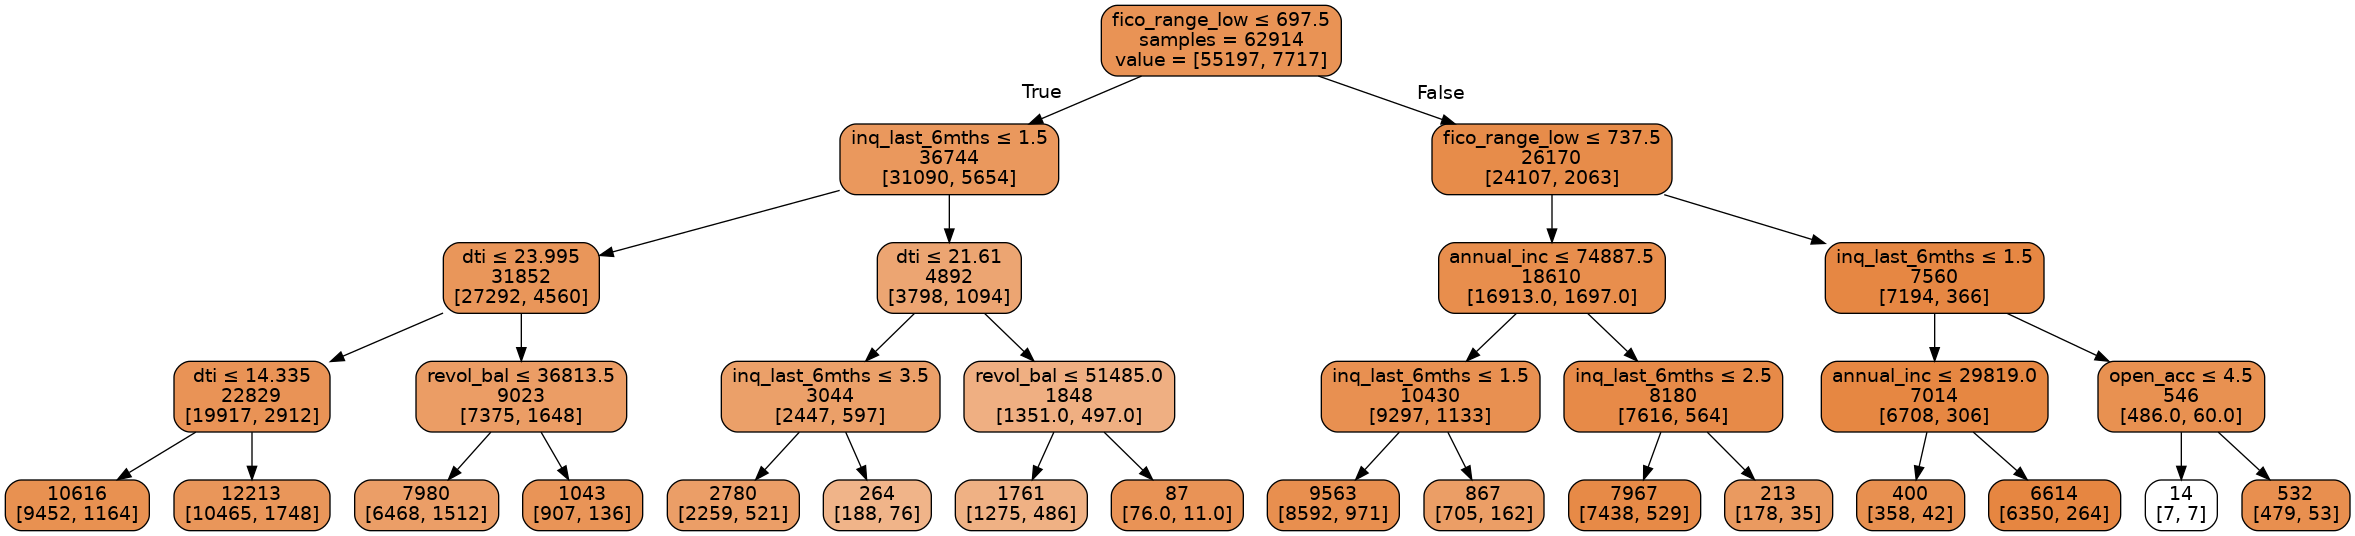

In [21]:
X = lcd_df.drop(columns=['charge_off', 'loan_status', 'loan_id', 'fico_range_high',])
y = lcd_df['charge_off']
train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.4, random_state=1)

tree = DecisionTreeClassifier(max_depth=4, random_state=1)
tree.fit(train_X, train_y)

plotDecisionTree(tree, feature_names=train_X.columns)

classificationSummary(train_y, tree.predict(train_X))
classificationSummary(valid_y, tree.predict(valid_X))

In [ ]:
This model used a Random Forest Classifier with 4 decision trees to predict 
the target outcome. The model had an accuracy of 0.87, meaning it correctly 
classified 87% of the validation records. However, accuracy alone may be 
misleading because the precision was only 0.18 and the recall was only 0.02. 
The precision score means that when the model predicted a positive case, it 
was correct only 18% of the time. The recall score means the model identified
only 2% of the actual positive cases.

Overall, this model is not very effective at finding the positive class. Even 
though the accuracy is high, the very low recall shows that the model is 
probably predicting the majority class most of the time and missing almost 
all of the important positive cases. This suggests that the data may be 
imbalanced, and a different model setup may be needed, such as adjusting 
class weights, changing the cutoff threshold, or using more trees in the 
random forest.